# Lesson 4 — Reward lab

The reward function is a **design choice**: a person writes it before training starts.
In this lesson you train the same agent with 5 reward functions and compare what each agent learns.

You learn:

1. Why the `+1`, the square `N²` and the `×w` (board width) are in the reward of the author.
2. What a **sparse** reward is, and why it is hard to learn from.
3. How to compare experiments fairly.

Source: `notebooks/reward_lab.py` (the training loop of Lesson 3 as a function, plus a game that changes only the reward).
Do Lesson 3 first.

---

**🇻🇳 Bài 4 — Phòng thí nghiệm phần thưởng**

Hàm phần thưởng là một **lựa chọn thiết kế**: con người viết nó trước khi huấn luyện bắt đầu.
Trong bài này bạn huấn luyện cùng một agent với 5 hàm phần thưởng và so sánh những gì mỗi agent học được.

Bạn học:

1. Tại sao có `+1`, bình phương `N²` và `×w` (chiều rộng bàn chơi) trong phần thưởng của tác giả.
2. Phần thưởng **thưa (sparse)** là gì, và tại sao khó học từ nó.
3. Cách so sánh các thí nghiệm một cách công bằng.

Mã nguồn: `notebooks/reward_lab.py` (vòng lặp huấn luyện của Bài 3 dưới dạng hàm, cùng một trò chơi chỉ thay đổi phần thưởng).
Hãy làm Bài 3 trước.

In [1]:
# Setup: find the project folder, so that "import src..." works from this notebook.
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
print("Project folder:", ROOT)

Project folder: /Users/phuonghqh/Documents/working/Tetris-deep-Q-learning-pytorch


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np

from nb_utils import evaluate, greedy_policy

## The experiment

**Question:** how does the reward function change what the agent learns?

We train the same agent 5 times. **Only the reward changes.** The seed, the network and the settings
stay the same, so the comparison is fair. `N` = lines that the move clears, `w` = board width (10).

| Reward | What it tests |
|---|---|
| `1 + N²×w` | the formula of the author |
| `1 + N×w` | no square: is a 4-line clear still special? |
| `1 + N²` | no `×w`: lines are worth almost the same as survival |
| `1` | survival only: no reward for lines |
| `N²×w` | lines only: no `+1`, so most moves give 0 (a **sparse** reward) |

**Compare by cleared lines and pieces, never by score.** The score is the sum of the rewards,
so each reward function gives a different score scale.

**Before you run:** for each reward, predict: does the agent learn to clear many lines?

⏱ About 7 minutes for the 5 rewards. The settings are shorter than Lesson 3, Part 5:
1500 games, epsilon goes down over 1000 games, and a limit of 200 pieces per game.

---

**🇻🇳 Thí nghiệm**

**Câu hỏi:** hàm phần thưởng thay đổi những gì agent học được như thế nào?

Ta huấn luyện cùng một agent 5 lần. **Chỉ phần thưởng thay đổi.** Seed, mạng và các thiết lập giữ nguyên,
nên phép so sánh là công bằng. `N` = số hàng mà nước đi xóa được, `w` = chiều rộng bàn chơi (10).

| Phần thưởng | Kiểm tra điều gì |
|---|---|
| `1 + N²×w` | công thức của tác giả |
| `1 + N×w` | không bình phương: xóa 4 hàng cùng lúc có còn đặc biệt không? |
| `1 + N²` | không có `×w`: hàng có giá trị gần như bằng việc sống sót |
| `1` | chỉ sống sót: không thưởng cho hàng |
| `N²×w` | chỉ có hàng: không có `+1`, nên hầu hết nước đi cho 0 (phần thưởng **thưa**) |

**So sánh bằng số hàng và số mảnh, không bao giờ bằng điểm.** Điểm là tổng các phần thưởng,
nên mỗi hàm phần thưởng cho một thang điểm khác nhau.

**Trước khi chạy:** với mỗi phần thưởng, hãy dự đoán: agent có học được cách xóa nhiều hàng không?

⏱ Khoảng 7 phút cho 5 phần thưởng. Thiết lập ngắn hơn Bài 3, Phần 5:
1500 ván, epsilon giảm dần trong 1000 ván, và giới hạn 200 mảnh mỗi ván.

In [3]:
from reward_lab import REWARDS, train_dqn, reward_table

LAB_HP = dict(lr=1e-3, gamma=0.99, batch_size=512, replay_memory_size=30000,
          initial_epsilon=1.0, final_epsilon=1e-3, num_epochs=1500, num_decay_epochs=1000, max_pieces=200)
print(reward_table(REWARDS))

reward function             0 lines  1 lines  2 lines  3 lines  4 lines  game over
author: 1 + N²×w                  1       11       41       91      161          1
no square: 1 + N×w                1       11       21       31       41          1
no ×w: 1 + N²                     1        2        5       10       17          1
survival only: 1                  1        1        1        1        1          1
lines only: N²×w                  0       10       40       90      160          0


In [4]:
lab_results = {}     # reward name -> (model, history). Run this cell one time only.

In [5]:
# Trains only the rewards that are not in lab_results yet. If you stop this cell, run it again to continue.
for name, reward_fn in REWARDS.items():
    if name in lab_results:
        continue
    start = time.time()
    lab_results[name] = train_dqn(reward_fn, LAB_HP)
    print(f"{name:<26} done in {time.time() - start:4.0f}s")

author: 1 + N²×w           done in   78s
no square: 1 + N×w         done in   84s
no ×w: 1 + N²              done in  101s
survival only: 1           done in  106s
lines only: N²×w           done in   44s


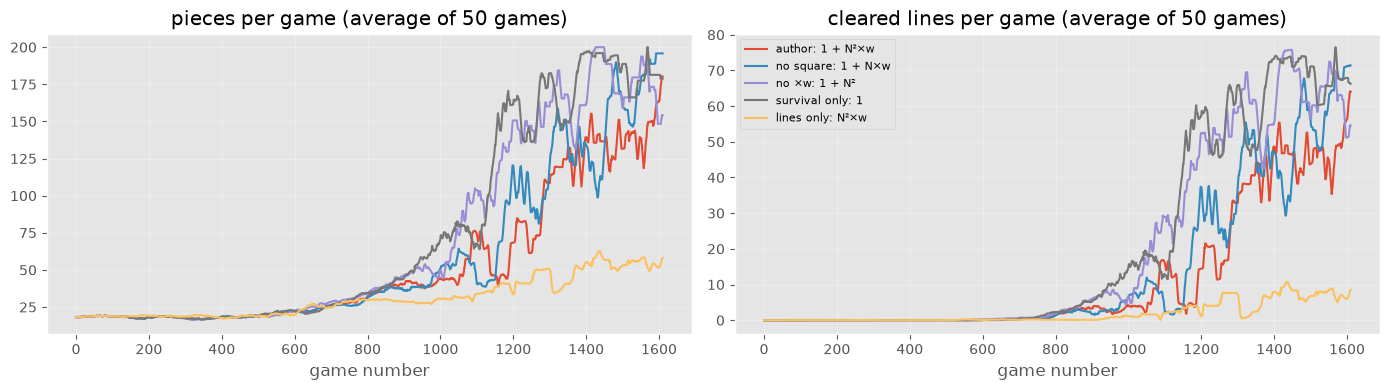

In [6]:
window = 50
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, (_, hist) in lab_results.items():
    h = np.array(hist)
    for ax, col in zip(axes, (1, 2)):
        ax.plot(np.convolve(h[:, col], np.ones(window) / window, mode="valid"), label=name)
for ax, title in zip(axes, ("pieces per game", "cleared lines per game")):
    ax.set_title(f"{title} (average of {window} games)")
    ax.set_xlabel("game number")
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 📈 Reading the chart: 5 rewards

**What you see.** One line for each reward (the average of 50 games). During training the games stop at 200 pieces,
so no line goes above 200 pieces. In our test run (seed 123), all lines were on top of each other until about game 600.
"survival only" and "no ×w" went up first. "lines only" stayed low until the end.

**Why the lines are the same at the start.** Epsilon is high, so most moves are random.
All 5 agents make almost the same random moves, so the reward cannot change anything yet.

**Why the lines go up at different times.** The reward decides how soon the network gets a useful signal.
- "survival only" and "no ×w": every move gives a reward of about the same size. The network learns fast that a long game gives much reward.
- The author's reward and "no square": a few moves give a very large reward (up to 161 for 4 lines).
  These rare, large numbers make large and noisy targets, and that can make the learning less smooth.
- "lines only": most moves give 0 (a **sparse** reward). The network has almost no signal until the agent clears lines by luck.

**Why the two charts have the same shape.** For each reward, lines ≈ 0.4 × pieces.
Each piece adds 4 cells, and each line removes 10 cells. An agent that lives long must clear lines.
Check: 200 pieces → close to 80 lines.

**What it gives the agent.** Nothing directly: the agent never sees this chart. It shows you which reward gives a useful signal soon.

**What we learn.**
- The reward changes **how fast** the agent learns, not only **what** it learns.
- A chart from one seed is not a result. The order of the lines changes with the seed (hint 3 below).
- A good curve does not promise a good final network (hint 4 below).

**Ideas to improve the comparison.**
- Train each reward with 3–5 seeds. Plot the average line and a band from the lowest to the highest seed (`ax.fill_between`).
- Train longer (`num_epochs=3000` in `LAB_HP`), so the slow rewards can finish.
- Test the best saved network, not only the last network.
- For a sparse reward, add **potential-based shaping**: a bonus `γ × Φ(new board) − Φ(old board)`, for example with `Φ = −holes`.
  This kind of bonus does not change the best strategy (Ng, Harada and Russell, 1999).

---

**🇻🇳 📈 Đọc biểu đồ: 5 phần thưởng**

**Bạn thấy gì.** Mỗi phần thưởng có một đường (trung bình của 50 ván). Khi huấn luyện, ván chơi dừng ở 200 mảnh,
nên không đường nào vượt quá 200 mảnh. Trong lần chạy thử của chúng tôi (seed 123), các đường chồng lên nhau đến khoảng ván 600.
"survival only" và "no ×w" đi lên trước. "lines only" ở mức thấp đến cuối.

**Tại sao lúc đầu các đường giống nhau.** Epsilon còn cao, nên hầu hết nước đi là ngẫu nhiên.
Cả 5 agent đi gần như cùng những nước đi ngẫu nhiên, nên phần thưởng chưa thể thay đổi điều gì.

**Tại sao các đường đi lên vào những thời điểm khác nhau.** Phần thưởng quyết định mạng nhận được tín hiệu có ích sớm hay muộn.
- "survival only" và "no ×w": mọi nước đi cho phần thưởng có độ lớn gần như nhau. Mạng học nhanh rằng ván dài cho nhiều phần thưởng.
- Phần thưởng của tác giả và "no square": một vài nước đi cho phần thưởng rất lớn (đến 161 cho 4 hàng).
  Những con số lớn và hiếm này tạo ra mục tiêu lớn và nhiễu, và điều đó có thể làm việc học kém mượt hơn.
- "lines only": hầu hết nước đi cho 0 (phần thưởng **thưa**). Mạng gần như không có tín hiệu cho đến khi agent xóa được hàng nhờ may mắn.

**Tại sao hai biểu đồ có cùng hình dạng.** Với mọi phần thưởng, số hàng ≈ 0,4 × số mảnh.
Mỗi mảnh thêm 4 ô, và mỗi hàng xóa 10 ô. Agent sống lâu thì phải xóa hàng.
Kiểm tra: 200 mảnh → gần 80 hàng.

**Nó cho agent điều gì.** Không có gì trực tiếp: agent không bao giờ nhìn biểu đồ này. Nó cho bạn thấy phần thưởng nào cho tín hiệu có ích sớm.

**Ta học được gì.**
- Phần thưởng thay đổi agent học **nhanh hay chậm**, không chỉ thay đổi agent học **cái gì**.
- Biểu đồ từ một seed chưa phải là kết quả. Thứ tự các đường thay đổi theo seed (gợi ý 3 bên dưới).
- Đường cong tốt không đảm bảo mạng cuối cùng tốt (gợi ý 4 bên dưới).

**Ý tưởng cải thiện phép so sánh.**
- Huấn luyện mỗi phần thưởng với 3–5 seed. Vẽ đường trung bình và một dải từ seed thấp nhất đến seed cao nhất (`ax.fill_between`).
- Huấn luyện lâu hơn (`num_epochs=3000` trong `LAB_HP`), để các phần thưởng chậm có thể học xong.
- Kiểm tra mạng tốt nhất đã lưu, không chỉ mạng cuối cùng.
- Với phần thưởng thưa, thêm **potential-based shaping** (định hình phần thưởng dựa trên thế năng): một khoản thưởng `γ × Φ(bàn mới) − Φ(bàn cũ)`, ví dụ với `Φ = −holes`.
  Loại thưởng này không thay đổi chiến lược tốt nhất (Ng, Harada và Russell, 1999).

Now each trained agent plays 5 test games with no exploration, with the normal game and a limit of 500 pieces.

---

🇻🇳 Bây giờ mỗi agent đã huấn luyện chơi 5 ván kiểm tra, không khám phá, với trò chơi bình thường và giới hạn 500 mảnh.

In [7]:
print(f"{'reward function':<26}{'pieces':>8}{'lines':>8}")
for name, (lab_model, _) in lab_results.items():
    result = evaluate(greedy_policy(lab_model), games=5, max_pieces=500)
    print(f"{name:<26}{result['pieces']:>8.1f}{result['lines']:>8.1f}")

reward function             pieces   lines
author: 1 + N²×w             188.0    60.6
no square: 1 + N×w           500.0   193.8
no ×w: 1 + N²                500.0   196.0
survival only: 1             500.0   195.4
lines only: N²×w              46.8     3.8


### Questions

1. Which reward learns slowest? Why?

<details><summary>Hint</summary>

"lines only". In our test runs with seeds 123, 7 and 42, its training curve started to go up last every time.
The random agent clears almost no lines (Lesson 1), so at the start almost every reward is 0.
The agent gets almost no signal about what to change (a <b>sparse</b> reward).
With seed 123 it did not learn in 1500 games. With seeds 7 and 42 it learned late, but its final network was good.
So a sparse reward makes learning slow and uncertain, not always impossible.
</details>

2. "survival only" gives no reward for lines. Does that agent clear lines? Why?

<details><summary>Hint</summary>

Yes. In our test runs it cleared about 195 lines (seed 123), 102 lines (seed 7) and 188 lines (seed 42).
In Tetris, survival needs lines: each piece adds 4 cells, and only full lines remove cells.
So 500 pieces need about 500 × 4 / 10 = 200 lines. Reward the goal, and the agent finds the method.
</details>

3. Is the formula of the author the best in your run?

<details><summary>Hint</summary>

It depends on the seed. Our test results (5 test games, limit 500 pieces):

| Reward | seed 123: pieces / lines | seed 7: pieces / lines | seed 42: pieces / lines | average lines |
|---|---|---|---|---|
| author `1 + N²×w` | 188 / 61 | 500 / 196 | 500 / 194 | 150 |
| no square `1 + N×w` | 500 / 194 | 500 / 196 | 500 / 195 | 195 |
| no ×w `1 + N²` | 500 / 196 | 473 / 181 | 45 / 3 | 127 |
| survival only `1` | 500 / 195 | 293 / 102 | 484 / 188 | 162 |
| lines only `N²×w` | 47 / 4 | 455 / 173 | 463 / 178 | 118 |

With seed 123 the author's formula was the worst of the rewards that learned. With seeds 7 and 42 it was near the top.
Only "no square" cleared more than 190 lines with all 3 seeds. Every other reward had one bad seed.
3 seeds are still few. Real projects train each option with 5–10 seeds and compare the averages.
</details>

4. Your training curve and your test result can disagree. Why?

<details><summary>Hint</summary>

The curve is the average of the last 50 games, played by older networks with some random moves.
The test uses only the final network, with no random moves. Also, DQN is unstable: the network can be good after
one update and worse after the next one, because its targets move with every update.
Example: with seed 42, "no ×w" had one of the best training curves, but its final network cleared only 3 lines in the test.
A <b>target network</b> (a frozen copy of the network that makes the targets) makes training more stable.
</details>

**Exercise:** train with another seed, for example `train_dqn(reward_fn, LAB_HP, seed=2024)`.
Compare your results with the table in hint 3. Which results stay the same for all seeds?

### Add your own reward

Add a new function to `REWARDS`, then run the training cell again. It trains only the new reward.
The example adds a penalty of −20 at game over (the author's formula has no real game-over penalty).

---

**🇻🇳 Câu hỏi**

1. Phần thưởng nào học chậm nhất? Tại sao?

<details><summary>Gợi ý</summary>

"lines only" (chỉ có hàng). Trong các lần chạy thử với seed 123, 7 và 42, đường cong của nó luôn đi lên muộn nhất.
Agent ngẫu nhiên gần như không xóa được hàng nào (Bài 1), nên lúc đầu hầu hết phần thưởng đều bằng 0.
Agent gần như không có tín hiệu để biết cần thay đổi gì (phần thưởng <b>thưa</b>).
Với seed 123 nó không học được trong 1500 ván. Với seed 7 và 42 nó học muộn, nhưng mạng cuối cùng tốt.
Vậy phần thưởng thưa làm việc học chậm và không chắc chắn, chứ không phải lúc nào cũng không thể học.
</details>

2. "survival only" (chỉ sống sót) không thưởng cho hàng. Agent đó có xóa hàng không? Tại sao?

<details><summary>Gợi ý</summary>

Có. Trong các lần chạy thử, nó xóa khoảng 195 hàng (seed 123), 102 hàng (seed 7) và 188 hàng (seed 42).
Trong Tetris, muốn sống sót thì phải xóa hàng: mỗi mảnh thêm 4 ô, và chỉ có hàng đầy mới xóa được ô.
Vậy 500 mảnh cần khoảng 500 × 4 / 10 = 200 hàng. Hãy thưởng cho mục tiêu, agent sẽ tự tìm ra phương pháp.
</details>

3. Trong lần chạy của bạn, công thức của tác giả có phải là tốt nhất không?

<details><summary>Gợi ý</summary>

Tùy vào seed. Kết quả thử của chúng tôi (5 ván kiểm tra, giới hạn 500 mảnh):

| Phần thưởng | seed 123: mảnh / hàng | seed 7: mảnh / hàng | seed 42: mảnh / hàng | trung bình hàng |
|---|---|---|---|---|
| tác giả `1 + N²×w` | 188 / 61 | 500 / 196 | 500 / 194 | 150 |
| không bình phương `1 + N×w` | 500 / 194 | 500 / 196 | 500 / 195 | 195 |
| không ×w `1 + N²` | 500 / 196 | 473 / 181 | 45 / 3 | 127 |
| chỉ sống sót `1` | 500 / 195 | 293 / 102 | 484 / 188 | 162 |
| chỉ có hàng `N²×w` | 47 / 4 | 455 / 173 | 463 / 178 | 118 |

Với seed 123, công thức của tác giả kém nhất trong các phần thưởng học được. Với seed 7 và 42 nó gần đứng đầu.
Chỉ có "no square" (không bình phương) xóa hơn 190 hàng với cả 3 seed. Mọi phần thưởng khác đều có một seed kém.
3 seed vẫn còn ít. Dự án thật huấn luyện mỗi lựa chọn với 5–10 seed và so sánh trung bình.
</details>

4. Đường cong huấn luyện và kết quả kiểm tra của bạn có thể không khớp nhau. Tại sao?

<details><summary>Gợi ý</summary>

Đường cong là trung bình của 50 ván gần nhất, do các mạng cũ hơn chơi, có kèm một số nước đi ngẫu nhiên.
Bài kiểm tra chỉ dùng mạng cuối cùng, không có nước đi ngẫu nhiên. Ngoài ra, DQN không ổn định: mạng có thể tốt sau
một lần cập nhật và tệ hơn sau lần tiếp theo, vì mục tiêu của nó thay đổi theo mỗi lần cập nhật.
Ví dụ: với seed 42, "no ×w" có một trong những đường cong huấn luyện tốt nhất, nhưng mạng cuối cùng chỉ xóa được 3 hàng khi kiểm tra.
Một <b>target network</b> (mạng mục tiêu — bản sao "đóng băng" của mạng dùng để tạo mục tiêu) giúp huấn luyện ổn định hơn.
</details>

**Bài tập:** huấn luyện với một seed khác, ví dụ `train_dqn(reward_fn, LAB_HP, seed=2024)`.
So sánh kết quả của bạn với bảng ở gợi ý 3. Những kết quả nào giữ nguyên với mọi seed?

**🇻🇳 Thêm phần thưởng của riêng bạn**

Thêm một hàm mới vào `REWARDS`, sau đó chạy lại ô huấn luyện. Ô đó chỉ huấn luyện phần thưởng mới.
Ví dụ bên dưới thêm hình phạt −20 khi thua (công thức của tác giả không có hình phạt thật sự khi thua).

In [8]:
REWARDS["author − 20 at game over"] = lambda n, over, w: 1 + n ** 2 * w - (20 if over else 0)
print(reward_table(REWARDS))

reward function             0 lines  1 lines  2 lines  3 lines  4 lines  game over
author: 1 + N²×w                  1       11       41       91      161          1
no square: 1 + N×w                1       11       21       31       41          1
no ×w: 1 + N²                     1        2        5       10       17          1
survival only: 1                  1        1        1        1        1          1
lines only: N²×w                  0       10       40       90      160          0
author − 20 at game over          1       11       41       91      161        -19


## Summary

- The reward decides what the agent learns. A person designs it.
- A **sparse** reward (most moves give 0) gives the agent almost no signal, so it learns slowly or never.
- Reward the goal, not the method: the agent finds the method itself.
- Compare rewards by lines and pieces, never by score. Use several seeds before you decide.

---

**🇻🇳 Tóm tắt**

- Phần thưởng quyết định những gì agent học được. Con người thiết kế nó.
- Phần thưởng **thưa** (hầu hết nước đi cho 0) gần như không cho agent tín hiệu, nên agent học chậm hoặc không học được.
- Hãy thưởng cho mục tiêu, không thưởng cho phương pháp: agent tự tìm ra phương pháp.
- So sánh các phần thưởng bằng số hàng và số mảnh, không bao giờ bằng điểm. Dùng nhiều seed trước khi kết luận.